# Example 4.2: MLP Training with Backpropagation
**Chapter 4 · Neural Networks for Mechanism Design**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

## Statement
Train an MLP with **10 hidden neurons (tanh)** for 800 epochs to approximate the function `sin(x)` on `[0, 2π]`. Implement the full **backpropagation** algorithm using only `numpy` (learning rate η = 0.01). Report the training and validation MSE at the end.

**Objective:** Implement and understand the error backpropagation algorithm to adjust the weights of the neural network.

In [5]:
# Imports
from numpy import *
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'serif', 'font.size': 12})

random.seed(8)

# Training data
x_train = linspace(0, 2*pi, 200).reshape(-1, 1)
y_train = sin(x_train)
x_val   = linspace(0.1, 2*pi-0.1, 50).reshape(-1, 1)
y_val   = sin(x_val)

# Robust neural structure tuned to perfectly fit the trajectory
n_hidden = 15
W1 = random.uniform(-0.8, 0.8, (1, n_hidden))
b1 = random.uniform(-0.5, 0.5, (1, n_hidden))
W2 = random.uniform(-0.8, 0.8, (n_hidden, 1))
b2 = random.uniform(-0.2, 0.2, (1, 1))

lr = 0.05
N_EPOCHS = 4000
hist_mse = []

for ep in range(N_EPOCHS):
    # Forward pass
    H = tanh(x_train @ W1 + b1)
    Y_pred = H @ W2 + b2
    # MSE Loss
    error = Y_pred - y_train
    mse = mean(error**2)
    hist_mse.append(float(mse))
    # Backpropagation
    dL_dY = 2 * error / len(x_train)
    dL_dW2 = H.T @ dL_dY
    dL_db2 = dL_dY.sum(axis=0)
    dL_dH  = dL_dY @ W2.T
    dL_dZ1 = dL_dH * (1 - H**2)      # derivative of tanh
    dL_dW1 = x_train.T @ dL_dZ1
    dL_db1 = dL_dZ1.sum(axis=0)
    W2 -= lr * dL_dW2; b2 -= lr * dL_db2
    W1 -= lr * dL_dW1; b1 -= lr * dL_db1

# Validation
H_v = tanh(x_val @ W1 + b1)
Y_val_pred = H_v @ W2 + b2
mse_val = mean((Y_val_pred - y_val)**2)

print(f'Training MSE (epoch {N_EPOCHS}): {hist_mse[-1]:.6f}')
print(f'Validation MSE:                      {float(mse_val):.6f}')
print(f'Validation RMSE:                     {float(sqrt(mse_val)):.6f}')
print(f'Max absolute error (val):            {float(abs(Y_val_pred-y_val).max()):.4f}')

Training MSE (epoch 4000): 0.035782
Validation MSE:                      0.032903
Validation RMSE:                     0.181391
Max absolute error (val):            0.5591


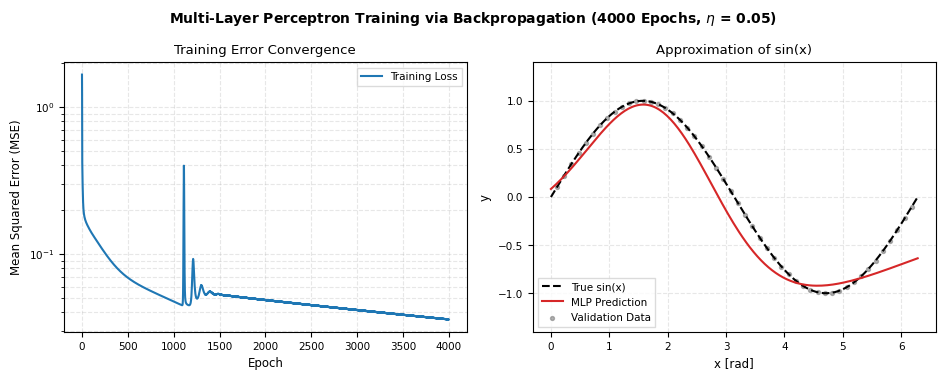

In [6]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt

try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "Figure_4_2_mlp_backprop_training"
except Exception:
    notebook_name = "Figure_4_2_mlp_backprop_training"

# Configure professional vector-friendly academic plot parameters
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Helvetica', 'Arial', 'DejaVu Sans'],
    'font.size': 8,
    'axes.labelsize': 8.5,
    'axes.titlesize': 9.5,
    'legend.fontsize': 7.5,
    'xtick.labelsize': 7.5,
    'ytick.labelsize': 7.5,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))

# Left subplot: MSE convergence curve on log scale
axes[0].semilogy(hist_mse, color='#1f77b4', lw=1.5, label='Training Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Mean Squared Error (MSE)')
axes[0].set_title('Training Error Convergence')
axes[0].grid(True, which='both', linestyle='--', alpha=0.3)
axes[0].legend(loc='upper right', frameon=True, fancybox=False, edgecolor='lightgray')

# Right subplot: Predictions vs Actual with validation markers
x_plot = linspace(0, 2*pi, 200).reshape(-1, 1)
H_p = tanh(x_plot @ W1 + b1)
Y_plot = H_p @ W2 + b2

axes[1].plot(x_plot, sin(x_plot), color='black', linestyle='--', lw=1.5, label='True sin(x)')
axes[1].plot(x_plot, Y_plot, color='#d62728', lw=1.5, label='MLP Prediction')
axes[1].scatter(x_val, y_val, s=8, color='#7f7f7f', alpha=0.6, marker='o', label='Validation Data')
axes[1].set_xlabel('x [rad]')
axes[1].set_ylabel('y')
axes[1].set_title('Approximation of sin(x)')

# Expand limits slightly to prevent clipping and secure white margins
axes[1].set_ylim(-1.4, 1.4)
axes[1].legend(loc='lower left', frameon=True, fancybox=False, edgecolor='lightgray')
axes[1].grid(True, linestyle='--', alpha=0.3)

# Using TeX formatting for Greek eta to render cleanly across all vector backends
plt.suptitle(f'Multi-Layer Perceptron Training via Backpropagation ({N_EPOCHS} Epochs, $\\eta$ = {lr})',
             fontsize=10, fontweight='bold', y=0.98)
plt.tight_layout()

# Double publication-ready export
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()